In [78]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import matplotlib



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_func as Treat_acoustic_func
importlib.reload(Treat_acoustic_func)
from Treat_acoustic_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic')
import Treat_acoustic_plotting as Treat_acoustic_plotting
importlib.reload(Treat_acoustic_plotting)
from Treat_acoustic_plotting import *




fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [79]:
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Acoustic\Sapphire\Change Au young modulus'

Sizes = ['test']
Spectra_data = {}
Colors = {}
compt=0

cm = plt.get_cmap('gist_rainbow')
Colors_list = [matplotlib.colors.to_hex(cm(1.*i/np.size(Sizes))) for i in range(np.size(Sizes))]


Fname_list = ['Young_modulud sweep - AR4']
n_parameters=2
Spectra_data['test']= get_raw_size_sweep_data_Nathan(dir_root, Fname_list, verbose=True)

Total size of raw data : 770
----------- Find spectra size -----------
idx start : 0
value start : (6.48473875240223+4.6216646218332516j)
end index : 69
value end : (48.67513072689706+0.2433521480030688j)
----------- Find spectra size -----------
idx start : 70
value start : (5.502132709709064+3.9275262409087204j)
end index : 139
value end : (47.32661262748338+0.002865799852017755j)
----------- Find spectra size -----------
idx start : 140
value start : (5.395890550797923+3.8442904016578465j)
end index : 209
value end : (45.30579771766299+0.036334329245110944j)
----------- Find spectra size -----------
idx start : 210
value start : (5.3958674684672845+3.8441812473456602j)
end index : 279
value end : (47.11240483087837+0.032745150342707405j)
----------- Find spectra size -----------
idx start : 280
value start : (5.3958435255054065+3.8440881928542305j)
end index : 349
value end : (48.847458907413646+0.02983889825540751j)
----------- Find spectra size -----------
idx start : 350
value st

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:97: ParserWarning:

Both a converter and dtype were specified for column % D (m) - only the converter will be used.

C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\Acoustic\Treat_acoustic_func.py:98: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.



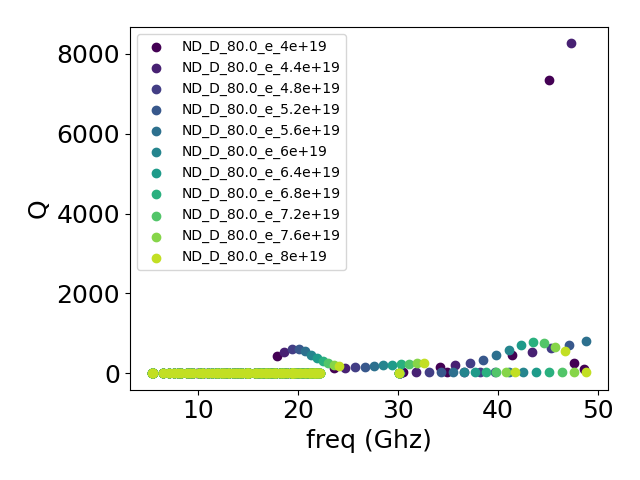

In [86]:
fig, ax= plt.subplots()
plot_all_raw_spectra(Spectra_data['test'], ax)
ax.legend(fontsize=10)
ax.set_xlabel('freq (Ghz)')
ax.set_ylabel('Q')
plt.tight_layout()

In [81]:
for key in Spectra_data :
    spectra = Spectra_data[key]
    get_modes_with_Q_selection(spectra, Q_th=3)

## def freq limit functions to extract Q factor

In [82]:
## For cylinder

def f1_low(ar) :
    return(38/(ar**0.5))

def f1_high(ar) :
    return(60/(ar**0.48))

## For round corner

def f2_low(ar) :
    return(35/(ar**0.5))

def f2_high(ar) :
    return(60/(ar**0.48))


## For round
def f3_low(ar) :
    return(38/(ar**0.5))

def f3_high(ar) :
    return(60/(ar**0.5))


Boundary_func = {}
Boundary_func['test'] = (f1_low, f1_high)


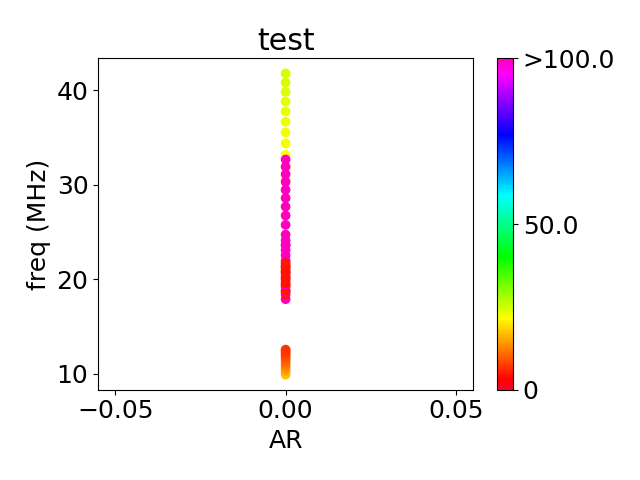

In [83]:
Q_max = 100
xlim = (1, 13)
ylim = (5, 50)
AR_array = np.linspace(1, 12, 1000)


for key in Spectra_data :
    spectra = Spectra_data[key]
   


    fig, ax = plt.subplots()
    #ax.set_xlim(xlim)
    #ax.set_ylim(ylim)
    plt.xlabel('AR')
    plt.ylabel('freq (MHz)')
    plt.title(key)
    


    plot_all_acoustic_modes(spectra, ax, Q_max = Q_max, n_modes = 5)
    plt.tight_layout()

    #ax.plot(AR_array, Boundary_func[key][0](AR_array), linestyle='--', color='grey')
    #ax.plot(AR_array, Boundary_func[key][1](AR_array), linestyle='--', color='grey')



KeyError: 'test'

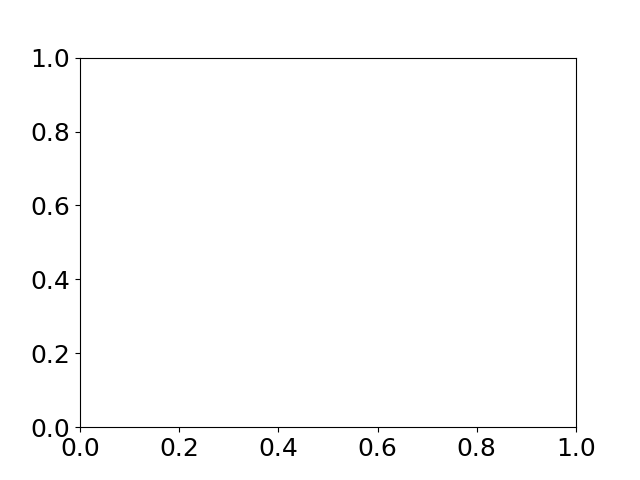

In [84]:
fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    


    for kkey in spectra :
        single_ND_modes = spectra[kkey]
        #print(np.sum(spectra['projection']))
        #print(spectra['eigen_freq'][np.argmax(spectra['projection'])])
        ax.scatter(single_ND_modes['AR']*np.ones(np.size(single_ND_modes['modes']['f'])), single_ND_modes['modes']['f'], color=Colors[key])

plt.title('Acoustic modes - all shapes')
plt.ylim(top=50)
plt.xlabel('AR')
plt.ylabel('freq (GHz)')
plt.tight_layout()

dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('freq(AR) - all shapes.pdf')
plt.savefig('freq(AR) - all shapes.png')



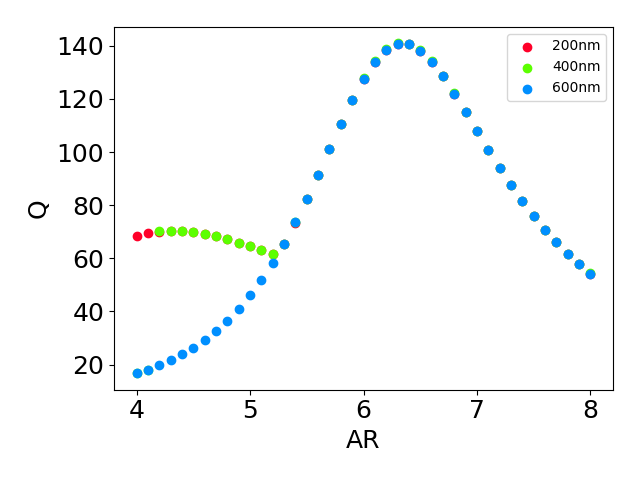

In [ ]:
AR_min = 1
AR_max = 12

fig, ax = plt.subplots()



for key in Spectra_data :
    spectra = Spectra_data[key]
    AR, Q = get_max_Q(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1],AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR, Q, color=Colors[key], label = key)


plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()




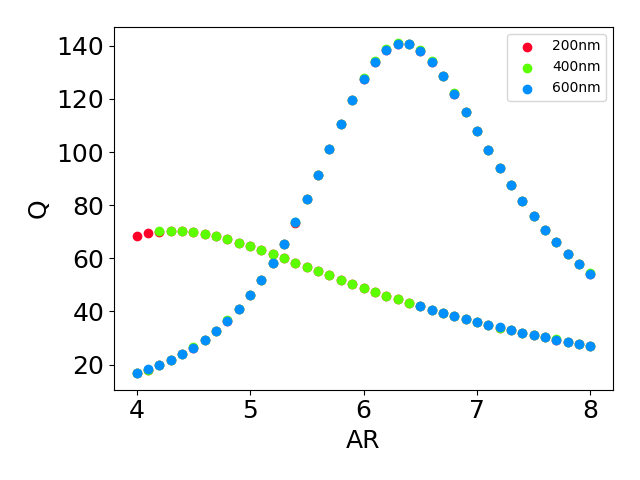

In [ ]:


AR_all_shapes = {}
Q_all_shapes = {}
Freq_all_shapes = {}

fig, ax = plt.subplots()

for key in Spectra_data :
    spectra = Spectra_data[key]
    AR_all_shapes[key],  Freq_all_shapes[key], Q_all_shapes[key] = get_Q_specific_bands(spectra, freq_low_func=Boundary_func[key][0], freq_high_func=Boundary_func[key][1], AR_min=AR_min, AR_max=AR_max)
    ax.scatter(AR_all_shapes[key],  Q_all_shapes[key], color=Colors[key], label = key)

plt.xlabel('AR')
plt.ylabel('Q')
plt.legend(fontsize=10)
plt.tight_layout()


dir_to_save = dir_root  + r'\Figures'
if not(os.path.exists(dir_to_save)) :
    os.mkdir(dir_to_save)
os.chdir(dir_to_save)
plt.savefig('Q(AR) - all shapes.pdf')
plt.savefig('Q(AR) - all shapes.png')

## Save data

In [ ]:
if 0 :
    for key in Spectra_data :
        spectra = Spectra_data[key]


        dir_to_save = dir_root + r'\\' + key + r'\Treated data'
        save_Q_with_AR_to_csv(dir_to_save, 'Selected acoustic modes', Q_all_shapes[key], AR_all_shapes[key], Freq_all_shapes[key])
        save_freq_with_AR_to_csv(dir_to_save, 'Q and freq', spectra)
